# Reading Data

In [10]:
import os
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr
import hmp
import pickle
from helper_functions import HalfSine, EvidenceAccumulation, simulate_from_hmpfit
import hmp
import hmp.io

# Reading data as in other notebooks
eeg_data_path = os.path.join('data/')#Declaring path where the eeg data is
subj_names = [x.split('.')[0] for x in os.listdir(eeg_data_path) if '.fif' in x]#Extracting subject name based on the file name
subj_files = [eeg_data_path+x+'.fif' for x in subj_names]#Create a list of files that can be read from the folder

sfreq = 250 #at what sampling rate we want the data, replace with 100Hz for speed/RAM
tstep = (1000/sfreq) #Time step for plotting

preprocessing=dict(sfreq=sfreq, pick_channels='eeg')

## added to load a specific subject
subj = '6_epo'                       # or a specific name, e.g. "sub-01"
one_file = [eeg_data_path + subj + '.fif']
print("First print:",os.getcwd(), subj_names)
print("End of first print")
epoch_data, info = hmp.io.read_mne_epochs(one_file,
                                          montage='biosemi64',
                                          preprocessing_kwargs=preprocessing)

#epoch_data, info = hmp.io.read_mne_epochs(subj_files, montage='biosemi64',preprocessing_kwargs=preprocessing)

# Remove baseline that is not modelled by HMP
epoch_data = epoch_data.sel(sample=range(epoch_data.sample.max().values))

First print: C:\Users\cleli\PycharmProjects\EEG_Predictions ['0_epo', '10_epo', '11_epo', '12_epo', '13_epo', '14_epo', '15_epo', '16_epo', '17_epo', '18_epo', '19_epo', '1_epo', '20_epo', '21_epo', '22_epo', '23_epo', '24_epo', '25_epo', '2_epo', '3_epo', '4_epo', '5_epo', '6_epo', '7_epo', '8_epo', '9_epo']
End of first print
Processing dataset 6
Reading C:\Users\cleli\PycharmProjects\EEG_Predictions\data\6_epo.fif ...
    Found the data of interest:
        t =    -199.22 ...    3000.00 ms
        0 CTF compensation matrices available
Adding metadata with 6 columns
1116 matching events found
No baseline correction applied
0 projection items activated
Epoch data will be decimated by 2 to achieve a sampling frequency of 256.0Hz


## Load HMP estimate

In [11]:
#Collecting previous estimation
# Loading probabilities
with open("data/estimation_files/estimates.pkl", 'rb') as input_file:
    estimates = pickle.load(input_file)
    
# Load the fitted model
with open("data/estimation_files/model.pkl", 'rb') as input_file:
    model = pickle.load(input_file)
    
# = HMP model object itself: its settings (bump width, distribution) and fitted parameters (the channel weights ω and the time parameters θ from the HMP paper)
# estimates = model outputs, model = model itself

weights =  hmp.utils.event_channels(epoch_data, estimates, mean=False).squeeze()
# epoch_data = return real EEG (loaded and prepared earlier in his code, in a format HMP understands).
#funtion: event_channels = for each trial and each event, takes the most likely time of the event (from estimates) and reads the value of every electrode at that time. 
#           mean=False = don’t average across trials: you get one scalp map per trial. 
#           With mean=True, you’d get one average map per event.

#           squeeze() = removes dimensions of size 1 (probably the group dimension, since there’s only one group).

times = hmp.utils.event_times(estimates, add_rt=True)
# most likely timepoint for each event + RT as last column

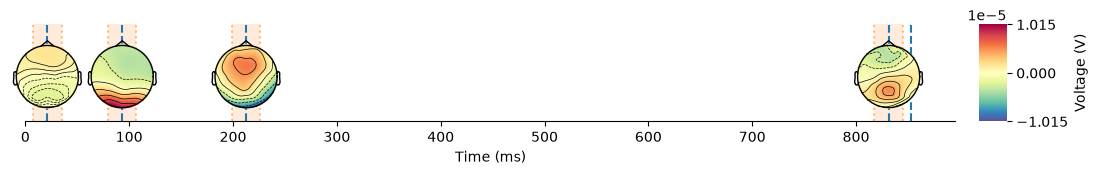

In [12]:
hmp.visu.plot_topo_timecourse(epoch_data, estimates, info, as_time=True, colorbar=True,)

# Simulations

In [14]:
# keep only the model’s trials that belong to the loaded participant
rec = str(epoch_data.recording.values[0])   # the participant you loaded
keep = np.where(times.recording.values == rec)[0]

times = times.isel(trial=keep)
weights = weights.isel(trial=keep)

print(rec, len(keep), "trials kept")

6 1093 trials kept


In [15]:
# An example using the default assumption of HMP regarding the pattern in the data
pattern_assumption = {0:HalfSine(sfreq, width=50), 1:HalfSine(sfreq, width=50), 
                      2:HalfSine(sfreq, width=50), 3:HalfSine(sfreq, width=50)}
# one pattern by event (here 4 events)
default_sim = simulate_from_hmpfit(epoch_data, weights, times, pattern_assumption)

# An example of a more realistic simulation
pattern_assumption = {0:HalfSine(sfreq, width=10), 1:HalfSine(sfreq, width=25), 
                      2:HalfSine(sfreq, width=25), 3:HalfSine(sfreq, width=200)}
informed_sim = simulate_from_hmpfit(epoch_data, weights, times, pattern_assumption)

Text(0.5, 1.0, 'Varying Half-Sine')

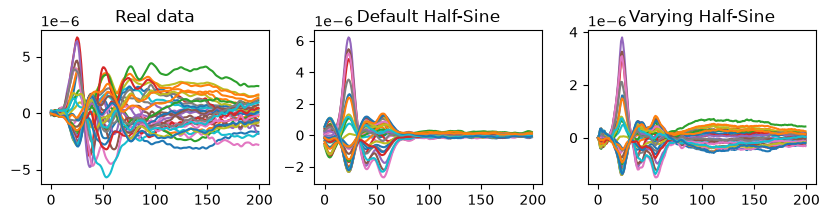

In [16]:
# Plotting the simulation
fig, ax = plt.subplots(1,3, figsize=(10, 2), sharey=False)
ax[0].plot(epoch_data.sel(sample=range(200)).stack({'trial':['epoch','recording']}).mean('trial').data.T);
ax[0].set_title('Real data')
ax[1].plot(default_sim.sel(sample=range(200)).stack({'trial':['epoch','recording']}).mean('trial').data.T);
ax[1].set_title('Default Half-Sine')
ax[2].plot(informed_sim.sel(sample=range(200)).stack({'trial':['epoch','recording']}).mean('trial').data.T);
ax[2].set_title('Varying Half-Sine')

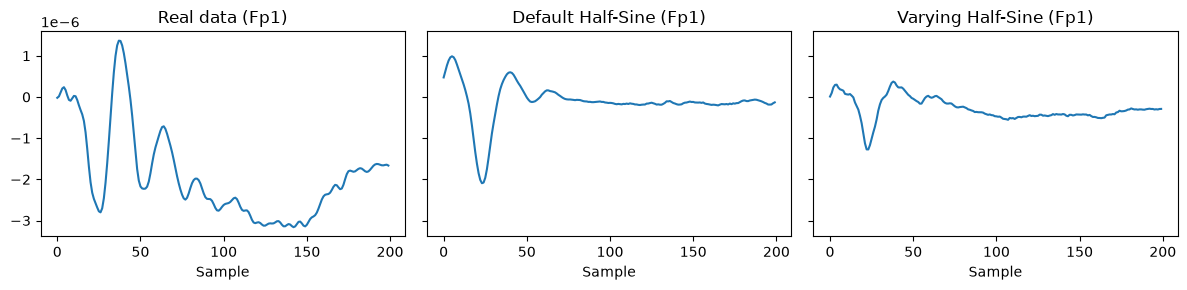

In [17]:
ch = 0   # first channel
n = 200

fig, ax = plt.subplots(1, 3, figsize=(12, 3), sharey=True)
for a, d, title in zip(ax,
                       [epoch_data, default_sim, informed_sim],
                       ['Real data', 'Default Half-Sine', 'Varying Half-Sine']):
    erp = (d.sel(sample=range(n))
             .isel(channel=ch)
             .stack({'trial': ['epoch', 'recording']})
             .mean('trial'))
    a.plot(erp.data)
    a.set_title(f'{title} ({str(epoch_data.channel.values[ch])})')
    a.set_xlabel('Sample')
plt.tight_layout()